# Visualization

## 1. Subtyping test

TO ADD

## 2. TME archetypes

### Tensorboard

In [24]:
# After checking results make sure to kill session via lsof -i :6006
# Run this in local terminal: ssh -L 6006:localhost:6006 ubuntu@172.23.74.19

%load_ext tensorboard

In [ ]:
%tensorboard --logdir '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/results/train_b8_lr1low_s1/' --host 0.0.0.0 --port 6006

### Grid search results

In [8]:
import glob
import os
import pickle

# Base directory path
base_dir = '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/results/'

# Find all .pkl files in subdirectories containing 'tuning'
pkl_files = glob.glob(os.path.join(base_dir, '**', '*tuning*', '*.pkl'), recursive=True)

# Load data from all matched .pkl files
data_list = []
for file in pkl_files:
    with open(file, 'rb') as f:
        data = pickle.load(f)
        data_list.append(data)

print(f"Loaded {len(data_list)} .pkl files")

results = data_list

Loaded 31 .pkl files


In [9]:
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import ConfusionMatrixDisplay

# Prepare lists to store performance metrics (F1 scores, etc.)
file_names = [file.split('/')[-2] for file in pkl_files]
f1_scores_weighted = []
accuracy_scores = []
precision_scores = []
recall_scores = []
confusion_matrices = []

# Loop through the results of each fold
for result in results:
    true_labels = []
    pred_labels = []
    for key, value in result.items():
        true_labels.append(value['label'])
        pred_labels.append(np.argmax(value['prob'], axis=1))  # predicted class
    
    # Convert lists to numpy arrays
    true_labels = np.array(true_labels)
    pred_labels = np.array(pred_labels)
    
    # Calculate the confusion matrix for the current fold
    cm = confusion_matrix(true_labels, pred_labels)
    confusion_matrices.append(cm)
    
    # Compute accuracy, precision, recall, and F1 scores
    accuracy_scores.append(accuracy_score(true_labels, pred_labels))
    precision_scores.append(precision_score(true_labels, pred_labels, average='weighted'))
    recall_scores.append(recall_score(true_labels, pred_labels, average='weighted'))
    
    # Calculate the weighted F1 score and append it to the list
    weighted_f1 = f1_score(true_labels, pred_labels, average='weighted')
    f1_scores_weighted.append(weighted_f1)

# Visualize performance scores across folds
metrics_df = pd.DataFrame({
    'Name': file_names,
    'Accuracy': accuracy_scores,
    'Precision (weighted)': precision_scores,
    'Recall (weighted)': recall_scores,
    'F1 Score (weighted)': f1_scores_weighted
})

metrics_df.sort_values('F1 Score (weighted)')

,Name,Accuracy,Precision (weighted),Recall (weighted),F1 Score (weighted)
0,tuning_b4_lr5vlow_s1,0.597403,0.623081,0.597403,0.592837
6,tuning_b32_lr1_s1,0.597403,0.623081,0.597403,0.592837
5,tuning_b16_lr1_s1,0.597403,0.623081,0.597403,0.592837
4,tuning_b8_lr1_s1,0.597403,0.623081,0.597403,0.592837
7,tuning_b4_lr2low_s1,0.623377,0.606101,0.623377,0.596146
10,tuning_b32_lr2low_s1,0.636364,0.616987,0.636364,0.608693
9,tuning_b16_lr2low_s1,0.636364,0.616987,0.636364,0.608693
8,tuning_b8_lr2low_s1,0.636364,0.616987,0.636364,0.608693
23,tuning_b4_lr2low_svm_s1,0.636364,0.627382,0.636364,0.616034
21,tuning_b16_lr1_svm_s1,0.623377,0.635427,0.623377,0.618376


### Training results

In [33]:
# Custom reading in of result files 

import glob
import os
import pickle

# Base directory path
base_dir = '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/results/'

# Find all .pkl files in subdirectories containing 'tuning'
pkl_files = glob.glob(os.path.join(base_dir, '**', '*train_b8_lr1low_do35_s1*','*.pkl*'), recursive=True)

# Load data from all matched .pkl files
data_list = []
for file in pkl_files:
    with open(file, 'rb') as f:
        data = pickle.load(f)
        data_list.append(data)

print(f"Loaded {len(data_list)} .pkl files")

results = data_list

Loaded 10 .pkl files


In [34]:
# Baseline accuracies and F1 scores
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import ConfusionMatrixDisplay
from collections import Counter

# Collect all true labels
true_labels = []
for result in results:
    for key, value in result.items():
        true_labels.append(value['label'])

true_labels = np.array(true_labels)

# Baseline 1: Most Frequent Class
most_common_class = Counter(true_labels).most_common(1)[0][0]
baseline_pred_mfc = np.full_like(true_labels, most_common_class)
baseline_f1_mfc = f1_score(true_labels, baseline_pred_mfc, average='weighted')
baseline_acc_mfc = accuracy_score(true_labels, baseline_pred_mfc)

# Baseline 2: Random Guessing Based on Class Distribution
class_counts = Counter(true_labels)
class_probs = np.array([class_counts[i] / len(true_labels) for i in range(len(class_counts))])
np.random.seed(42) 
baseline_pred_random = np.random.choice(list(class_counts.keys()), size=len(true_labels), p=class_probs)
baseline_f1_random = f1_score(true_labels, baseline_pred_random, average='weighted')
baseline_acc_random = accuracy_score(true_labels, baseline_pred_random)

print(f"Baseline F1 Score (Most Frequent Class): {baseline_f1_mfc:.4f}")
print(f"Baseline F1 Score (Random Guessing): {baseline_f1_random:.4f}")

Baseline F1 Score (Most Frequent Class): 0.3446
Baseline F1 Score (Random Guessing): 0.3077


In [35]:
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import ConfusionMatrixDisplay

# Prepare lists to store performance metrics (F1 scores, etc.)
file_names = [file.split('/')[-2] for file in pkl_files]
f1_scores_weighted = []
accuracy_scores = []
precision_scores = []
recall_scores = []
confusion_matrices = []

# Loop through the results of each fold
for result in results:
    true_labels = []
    pred_labels = []
    for key, value in result.items():
        true_labels.append(value['label'])
        pred_labels.append(np.argmax(value['prob'], axis=1))  # predicted class
    
    # Convert lists to numpy arrays
    true_labels = np.array(true_labels)
    pred_labels = np.array(pred_labels)

    # Calculate the confusion matrix for the current fold
    cm = confusion_matrix(true_labels, pred_labels)
    confusion_matrices.append(cm)
    
    # Compute accuracy, precision, recall, and F1 scores
    accuracy_scores.append(accuracy_score(true_labels, pred_labels))
    precision_scores.append(precision_score(true_labels, pred_labels, average='weighted'))
    recall_scores.append(recall_score(true_labels, pred_labels, average='weighted'))
    
    # Calculate the weighted F1 score and append it to the list
    weighted_f1 = f1_score(true_labels, pred_labels, average='weighted')
    f1_scores_weighted.append(weighted_f1)

# Visualize performance scores across folds
metrics_df = pd.DataFrame({
    'Name': file_names,
    'Accuracy': accuracy_scores,
    'Precision (weighted)': precision_scores,
    'Recall (weighted)': recall_scores,
    'F1 Score (weighted)': f1_scores_weighted
})

metrics_df.sort_values('F1 Score (weighted)')

,Name,Accuracy,Precision (weighted),Recall (weighted),F1 Score (weighted)
2,train_b8_lr1low_do35_s1,0.607143,0.605617,0.607143,0.602682
6,train_b8_lr1low_do35_s1,0.628205,0.644094,0.628205,0.632911
5,train_b8_lr1low_do35_s1,0.641026,0.640947,0.641026,0.639863
0,train_b8_lr1low_do35_s1,0.675325,0.674563,0.675325,0.664524
3,train_b8_lr1low_do35_s1,0.683544,0.680027,0.683544,0.676543
1,train_b8_lr1low_do35_s1,0.720000,0.723704,0.720000,0.721102
4,train_b8_lr1low_do35_s1,0.734177,0.735397,0.734177,0.734307
9,train_b8_lr1low_do35_s1,0.740741,0.742938,0.740741,0.741618
7,train_b8_lr1low_do35_s1,0.762500,0.764167,0.762500,0.760990
8,train_b8_lr1low_do35_s1,0.765432,0.779817,0.765432,0.762653


In [36]:
# Add AUC (ROC, PR) 

from sklearn.metrics import precision_recall_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize

# Initialize list to store AUC-PR values
auc_pr_scores = []
auc_roc_scores = []

# Loop through each fold
for result in results:
    true_labels = []
    pred_probs = []

    for key, value in result.items():
        true_labels.append(value['label'])
        pred_probs.append(value['prob'])

    true_labels = np.array(true_labels)
    pred_probs = np.array(pred_probs).reshape(len(true_labels), -1) 

    # Binarize true labels for multi-class AUC-PR
    true_labels_bin = label_binarize(true_labels, classes=[0, 1, 2])

    # Compute AUC-PR for each class (One-vs-Rest)
    auc_pr_values = []
    
    for class_idx in [0,1,2]:  
        # Correctly binarize true labels for this class (1D binary array)
        true_labels_class = true_labels_bin[:,class_idx]  

        # Extract the correct probabilities as a 1D array
        pred_probs_class = pred_probs[:, class_idx]

        # Compute Precision-Recall curve
        precision, recall, _ = precision_recall_curve(
            true_labels_class,          
            pred_probs_class             
        )
    
        # Calculate AUC-PR for this class
        auc_pr_values.append(auc(recall, precision))

    # Average AUC-PR scores (macro average)
    auc_pr_scores.append(np.mean(auc_pr_values))

    # Compute ROC-AUC score using 'ovr' for multi-class
    roc_auc = roc_auc_score(true_labels_bin, pred_probs, multi_class='ovr', average='weighted')
    auc_roc_scores.append(roc_auc)

metrics_df['AUC_PR'] = auc_pr_scores
metrics_df['AUC_ROC'] = auc_roc_scores

metrics_df.sort_values('AUC_ROC')

,Name,Accuracy,Precision (weighted),Recall (weighted),F1 Score (weighted),AUC_PR,AUC_ROC
2,train_b8_lr1low_do35_s1,0.607143,0.605617,0.607143,0.602682,0.669651,0.784925
6,train_b8_lr1low_do35_s1,0.628205,0.644094,0.628205,0.632911,0.698563,0.797574
9,train_b8_lr1low_do35_s1,0.740741,0.742938,0.740741,0.741618,0.728100,0.819661
5,train_b8_lr1low_do35_s1,0.641026,0.640947,0.641026,0.639863,0.731554,0.824651
0,train_b8_lr1low_do35_s1,0.675325,0.674563,0.675325,0.664524,0.741727,0.835057
3,train_b8_lr1low_do35_s1,0.683544,0.680027,0.683544,0.676543,0.740148,0.840186
4,train_b8_lr1low_do35_s1,0.734177,0.735397,0.734177,0.734307,0.810971,0.857266
1,train_b8_lr1low_do35_s1,0.720000,0.723704,0.720000,0.721102,0.797550,0.865414
8,train_b8_lr1low_do35_s1,0.765432,0.779817,0.765432,0.762653,0.842084,0.889823
7,train_b8_lr1low_do35_s1,0.762500,0.764167,0.762500,0.760990,0.836472,0.893954


In [37]:
mean_F1 = f"Mean F1: {metrics_df['F1 Score (weighted)'].mean():.3f} +- {metrics_df['F1 Score (weighted)'].std():.3f}"
mean_AUC = f"Mean ROC AUC: {metrics_df['AUC_ROC'].mean():.3f} +- {metrics_df['AUC_ROC'].std():.3f}"

print(mean_F1)
print(mean_AUC)

Mean F1: 0.694 +- 0.058
Mean ROC AUC: 0.841 +- 0.036


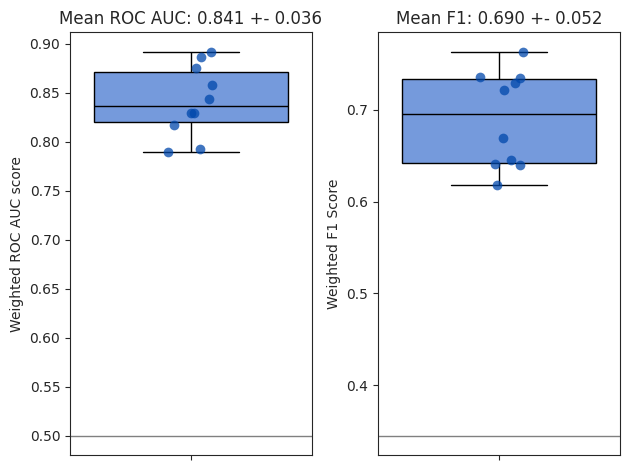

In [32]:
sns.set_style('ticks')
plt.figure()
plt.subplot(1, 2, 1)
sns.boxplot(data=metrics_df['AUC_ROC'], color = '#6495ED',
            boxprops={'edgecolor': 'black'},  medianprops={'color': 'black'}, whiskerprops={'color': 'black'}, capprops={'color': 'black'}, 
            showfliers=False)
sns.stripplot(data=metrics_df['AUC_ROC'], color = '#0047AB', alpha = 0.75, size=7)
plt.axhline(0.5, color = "grey", linestyle='-', linewidth=1, label='MFC Baseline')
plt.ylabel('Weighted ROC AUC score')
plt.title(mean_AUC)

plt.subplot(1, 2, 2)
sns.boxplot(data=metrics_df['F1 Score (weighted)'], color = '#6495ED',
            boxprops={'edgecolor': 'black'},  medianprops={'color': 'black'}, whiskerprops={'color': 'black'}, capprops={'color': 'black'}, 
            showfliers=False)
sns.stripplot(data=metrics_df['F1 Score (weighted)'], color = '#0047AB', alpha = 0.75, size=7)
plt.axhline(baseline_f1_mfc, color = "grey", linestyle='-', linewidth=1, label='MFC Baseline')
#plt.axhline(baseline_f1_random, color='grey', linestyle='-', linewidth=2, label='Random Baseline')
plt.ylabel('Weighted F1 Score')
plt.title(mean_F1)


plt.tight_layout()
plt.show()

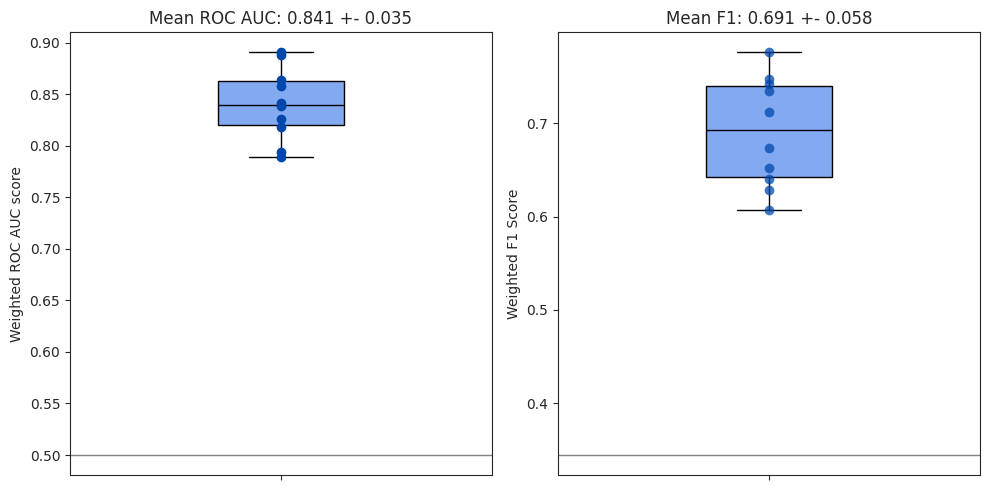

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('ticks')

plt.figure(figsize=(10, 5))

# Box 1: AUC_ROC
plt.subplot(1, 2, 1)
sns.boxplot(y=metrics_df['AUC_ROC'], 
            width = 0.3,
            color=None, 
            boxprops=dict(facecolor=(100/255, 149/255, 237/255, 0.8), edgecolor = 'black'),
            #boxprops={'edgecolor': 'black'},
            medianprops={'color': 'black'},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            showfliers=False)
sns.stripplot(y=metrics_df['AUC_ROC'], 
              color='#0047AB', 
              size=7, 
              jitter=False)
plt.axhline(0.5, color="grey", linestyle='-', linewidth=1, label='MFC Baseline')
plt.ylabel('Weighted ROC AUC score')
plt.title(mean_AUC)

# Box 2: F1 Score
plt.subplot(1, 2, 2)
sns.boxplot(y=metrics_df['F1 Score (weighted)'], 
            width=0.3, 
            color=None, 
            boxprops=dict(facecolor=(100/255, 149/255, 237/255, 0.8), edgecolor = 'black'),
            medianprops={'color': 'black'},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            showfliers=False)
sns.stripplot(y=metrics_df['F1 Score (weighted)'], color='#0047AB', alpha=0.75, size=7, jitter=False)
plt.axhline(baseline_f1_mfc, color="grey", linestyle='-', linewidth=1, label='MFC Baseline')
# plt.axhline(baseline_f1_random, color='grey', linestyle='-', linewidth=2, label='Random Baseline')
plt.ylabel('Weighted F1 Score')
plt.title(mean_F1)

plt.tight_layout()
plt.show()


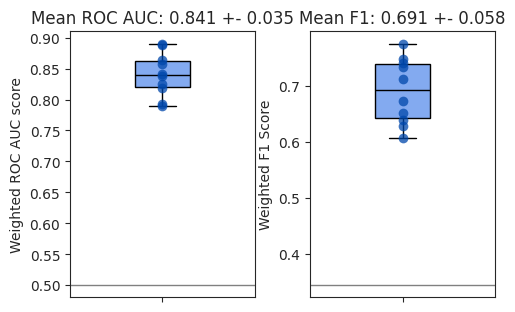

In [21]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import os

mpl.rcParams['pdf.fonttype'] = 42   # Use TrueType fonts (editable text in PDF)
mpl.rcParams['ps.fonttype'] = 42

sns.set_style('ticks')

fig, axes = plt.subplots(1, 2, figsize=(6, 5), gridspec_kw={'width_ratios': [1, 1]})  # Narrower figure

# Color as RGBA tuple for alpha
box_color_rgba = (100/255, 149/255, 237/255, 0.8)  # #6495ED with alpha=0.8

# --- Subplot 1: AUC_ROC ---
sns.boxplot(
    y=metrics_df['AUC_ROC'],
    ax=axes[0],
    width=0.3,
    color=None,
    boxprops=dict(facecolor=box_color_rgba, edgecolor='black'),
    medianprops={'color': 'black'},
    whiskerprops={'color': 'black'},
    capprops={'color': 'black'},
    showfliers=False
)
sns.stripplot(
    y=metrics_df['AUC_ROC'],
    ax=axes[0],
    color='#0047AB',
    alpha=0.75,
    size=7,
    jitter=False
)
axes[0].axhline(0.5, color='grey', linestyle='-', linewidth=1)
axes[0].set_ylabel('Weighted ROC AUC score')
axes[0].set_title(mean_AUC)

# --- Subplot 2: F1 Score ---
sns.boxplot(
    y=metrics_df['F1 Score (weighted)'],
    ax=axes[1],
    width=0.3,
    color=None,
    boxprops=dict(facecolor=box_color_rgba, edgecolor='black'),
    medianprops={'color': 'black'},
    whiskerprops={'color': 'black'},
    capprops={'color': 'black'},
    showfliers=False
)
sns.stripplot(
    y=metrics_df['F1 Score (weighted)'],
    ax=axes[1],
    color='#0047AB',
    alpha=0.75,
    size=7,
    jitter=False
)
axes[1].axhline(baseline_f1_mfc, color='grey', linestyle='-', linewidth=1)
axes[1].set_ylabel('Weighted F1 Score')
axes[1].set_title(mean_F1)

plt.tight_layout()

# Export to PDF
export_path = '/mnt/central_nas/rcc_volume/RCC/figures/HE/CLAM_Train_F1_ROC_F1_Box.pdf'
fig.set_size_inches(5,3) 
plt.savefig(export_path, format='pdf')

plt.show()


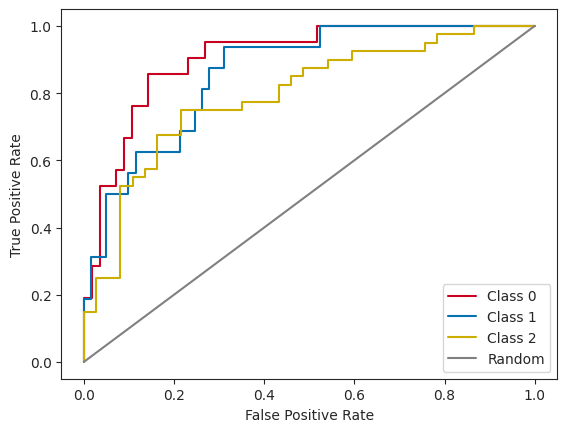

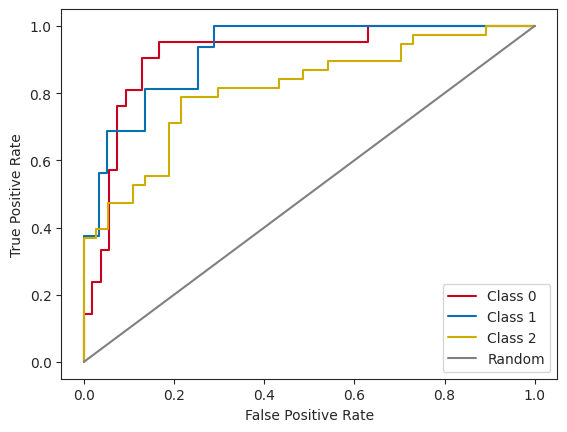

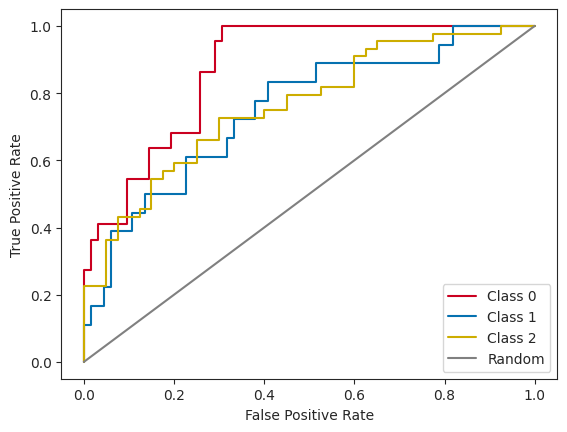

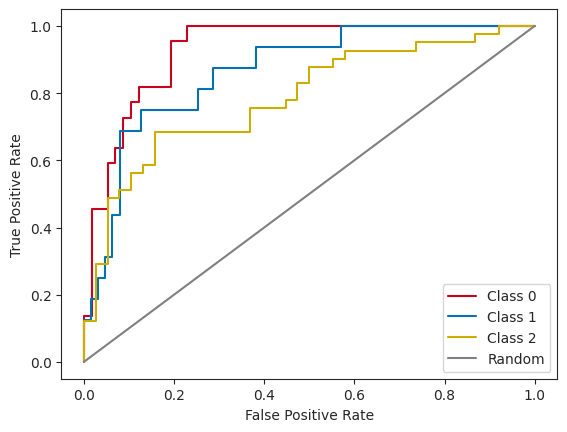

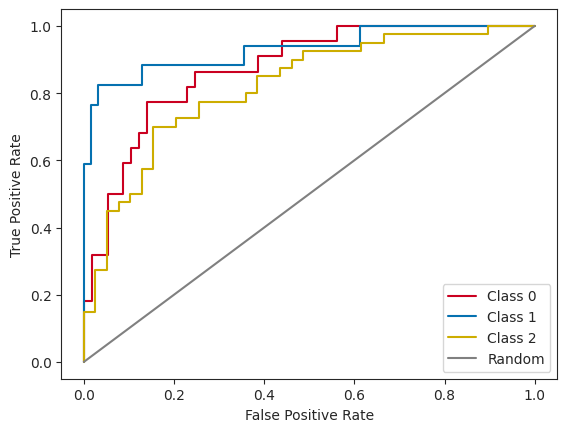

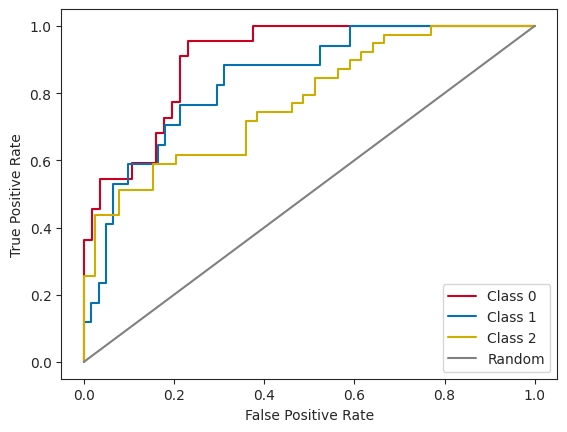

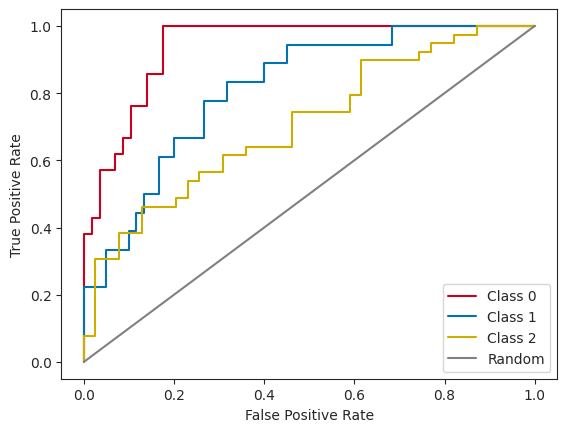

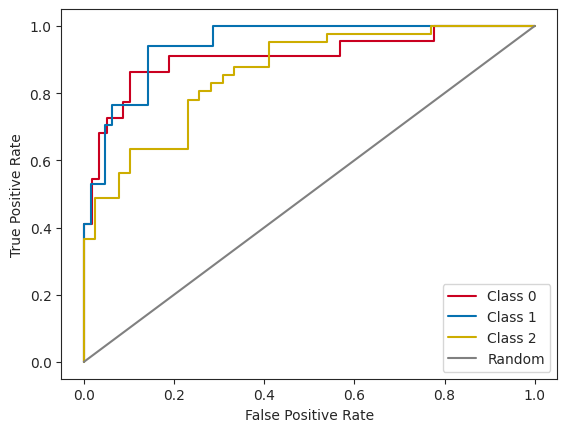

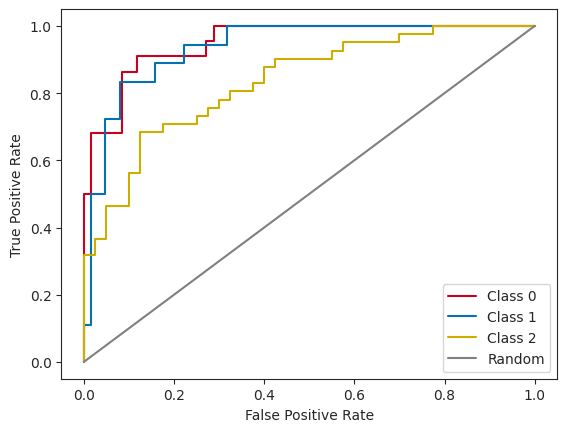

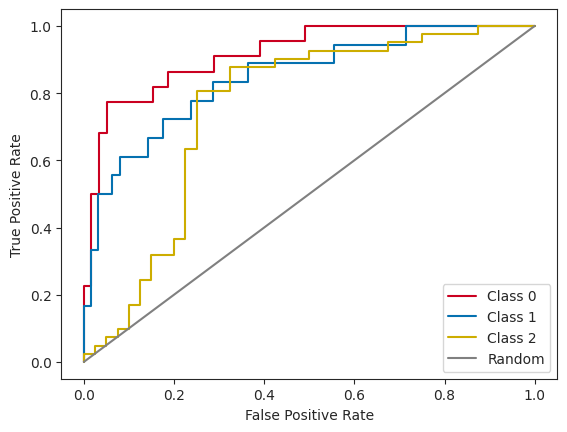

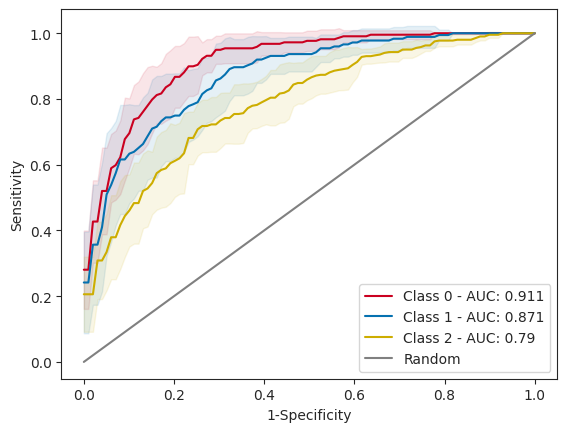

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize

# Initialize lists to store data for ROC and AUC-PR across folds
fpr_all = {0: [], 1: [], 2: []}  # To store FPR for each class
tpr_all = {0: [], 1: [], 2: []}  # To store TPR for each class
precision_all = {0: [], 1: [], 2: []}  # To store Precision for each class
recall_all = {0: [], 1: [], 2: []}  # To store Recall for each class
auc_scores = {0: [], 1: [], 2: []}  # To store ROC AUC scores for each class

# Define a color map for each class
class_colors = {0: '#CA0020', 1: '#0571B0', 2: '#cdad00'}

sns.set_style('ticks')

# Loop through each fold in results
for result in results:
    true_labels = []
    pred_probs = []

    for key, value in result.items():
        true_labels.append(value['label'])
        pred_probs.append(value['prob'])

    true_labels = np.array(true_labels)
    pred_probs = np.array(pred_probs).reshape(len(true_labels), -1) 

    # Binarize true labels for multi-class ROC and AUC-PR
    true_labels_bin = label_binarize(true_labels, classes=[0, 1, 2])

    # ROC curve visualization for this fold
    for class_idx in [0, 1, 2]:
        # Get true labels and predicted probabilities for this class
        true_labels_class = true_labels_bin[:, class_idx]
        pred_probs_class = pred_probs[:, class_idx]
        
        # Compute ROC curve
        fpr, tpr, _ = roc_curve(true_labels_class, pred_probs_class)
        #roc_auc = auc(fpr, tpr)  #Calculate AUC
        roc_auc = roc_auc_score(true_labels_class, pred_probs_class, multi_class='ovr', average='weighted')

        # Store ROC curve data for this class
        fpr_all[class_idx].append(fpr)
        tpr_all[class_idx].append(tpr)

        # Store ROC AUC for this class
        auc_scores[class_idx].append(roc_auc)

        # Plot ROC curve for the class
        plt.plot(fpr, tpr, label=f'Class {class_idx}', color = class_colors[class_idx])
    
    # Plot random chance (diagonal)
    plt.plot([0, 1], [0, 1], color = 'grey', linestyle = '-', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')

    plt.show()

# Interpolate the FPR and TPR values for each class
n_points = 100  # Number of points to interpolate to (more fine-grained)
fpr_interpolated = {0: [], 1: [], 2: []}
tpr_interpolated = {0: [], 1: [], 2: []}

for class_idx in [0, 1, 2]:
    # Get the FPR and TPR for each fold
    fprs = fpr_all[class_idx]
    tprs = tpr_all[class_idx]
    
    # Interpolate the FPR and TPR values to the same number of points
    mean_fpr = np.linspace(0, 1, n_points)
    mean_tpr = np.mean([np.interp(mean_fpr, fpr, tpr) for fpr, tpr in zip(fprs, tprs)], axis=0)

    fpr_interpolated[class_idx] = mean_fpr
    tpr_interpolated[class_idx] = mean_tpr

# Compute the average ROC AUC and standard deviation for each class
roc_auc_mean = {class_idx: np.mean(auc_scores[class_idx]) for class_idx in [0, 1, 2]}
roc_auc_std = {class_idx: np.std(auc_scores[class_idx]) for class_idx in [0, 1, 2]}

# ROC curve plot (average across folds with SD)
for class_idx in [0, 1, 2]:
    # Compute mean and std for FPR and TPR
    tpr_std = np.std([np.interp(fpr_interpolated[class_idx], fpr, tpr) for fpr, tpr in zip(fpr_all[class_idx], tpr_all[class_idx])], axis=0)

    # Plot the average ROC curve
    plt.plot(fpr_interpolated[class_idx], tpr_interpolated[class_idx], label=f'Class {class_idx} - AUC: {roc_auc_mean[class_idx]:.3}', color = class_colors[class_idx])
    plt.fill_between(fpr_interpolated[class_idx], tpr_interpolated[class_idx] - tpr_std, tpr_interpolated[class_idx] + tpr_std, color=class_colors[class_idx], alpha=0.1)  # SD shading

# Plot random chance (diagonal)
plt.plot([0, 1], [0, 1], color = 'grey', linestyle = '-', label='Random')
plt.xlabel('1-Specificity')
plt.ylabel('Sensitivity')
plt.legend(loc='lower right')
plt.show()

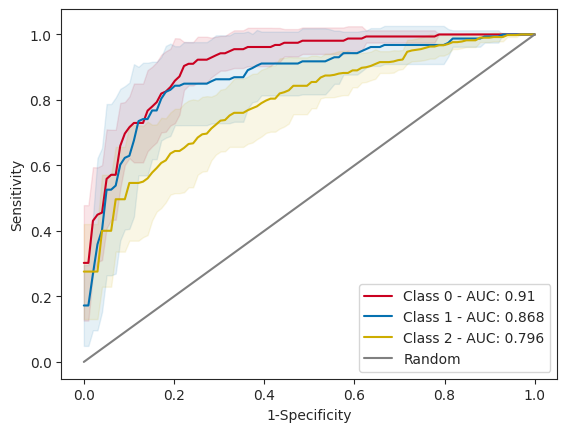

In [29]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import matplotlib as mpl
import seaborn as sns
import os

mpl.rcParams['pdf.fonttype'] = 42   # Use TrueType fonts (editable text in PDF)
mpl.rcParams['ps.fonttype'] = 42

# ROC curve plot (average across folds with SD)
for class_idx in [0, 1, 2]:
    # Compute mean and std for FPR and TPR
    tpr_std = np.std([np.interp(fpr_interpolated[class_idx], fpr, tpr) for fpr, tpr in zip(fpr_all[class_idx], tpr_all[class_idx])], axis=0)

    # Plot the average ROC curve
    plt.plot(fpr_interpolated[class_idx], tpr_interpolated[class_idx], label=f'Class {class_idx} - AUC: {roc_auc_mean[class_idx]:.3}', color = class_colors[class_idx])
    plt.fill_between(fpr_interpolated[class_idx], tpr_interpolated[class_idx] - tpr_std, tpr_interpolated[class_idx] + tpr_std, color=class_colors[class_idx], alpha=0.1)  # SD shading

# Plot random chance (diagonal)
plt.plot([0, 1], [0, 1], color = 'grey', linestyle = '-', label='Random')
plt.xlabel('1-Specificity')
plt.ylabel('Sensitivity')
plt.legend(loc='lower right')

# Export to PDF
export_path = '/mnt/central_nas/rcc_volume/RCC/figures/HE/CLAM_Train_ROCCurve.pdf'
fig.set_size_inches(5,3) 
plt.savefig(export_path, format='pdf')

plt.show()

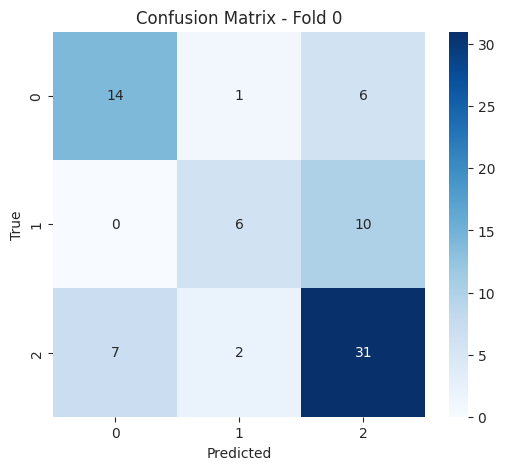

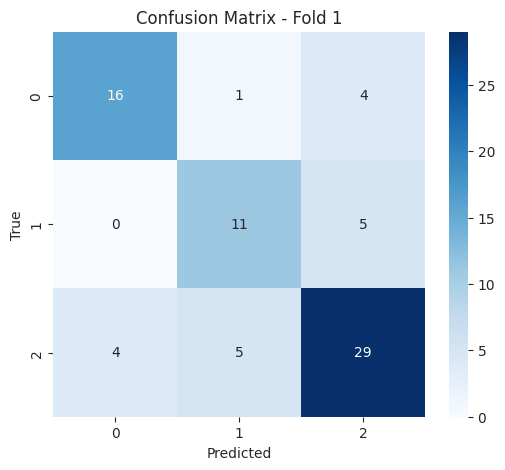

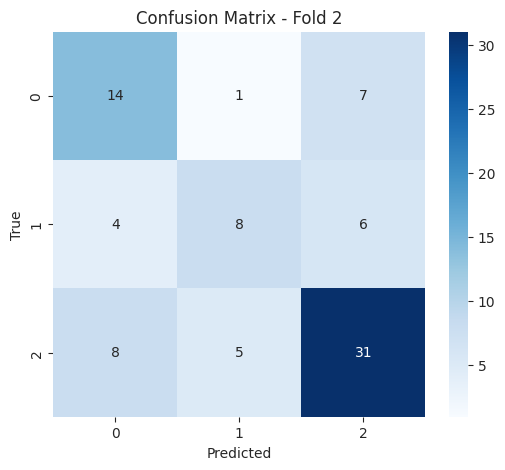

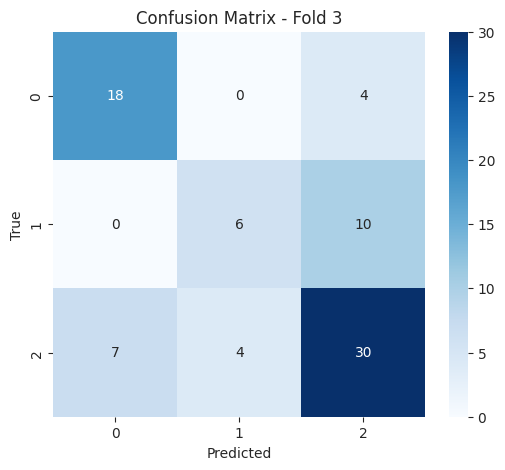

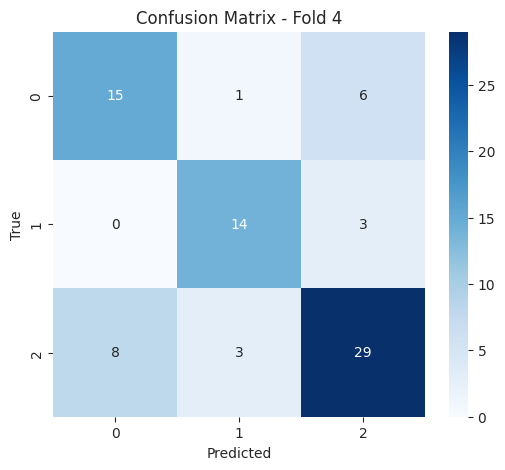

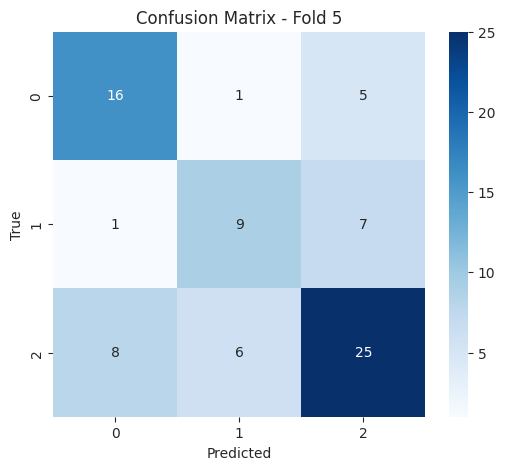

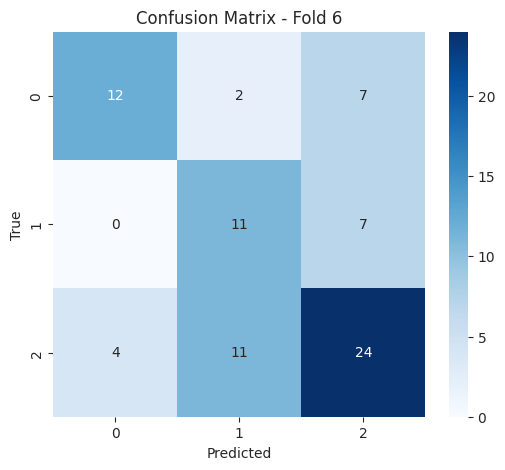

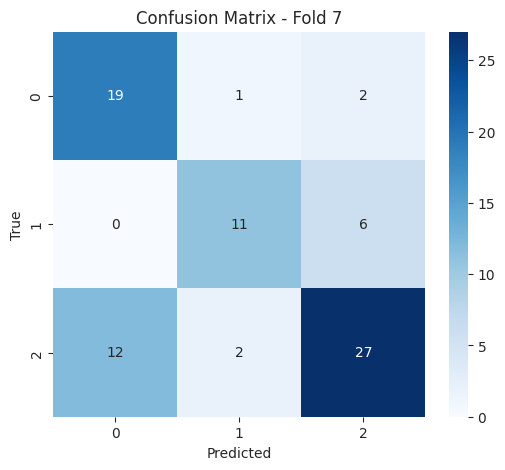

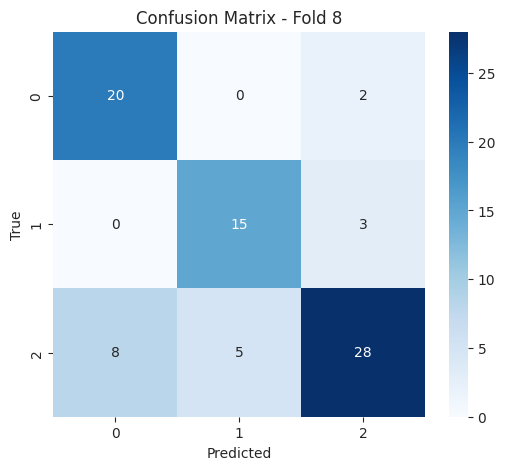

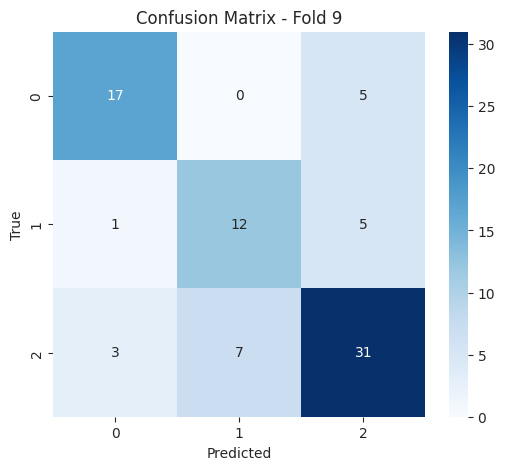

In [15]:
# Visualize Confusion Matrix for each fold
for i, cm in enumerate(confusion_matrices):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1, 2], yticklabels=[0, 1, 2])
    plt.title(f'Confusion Matrix - Fold {i}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

Notes: These performance metrics are currently estimated on a slide-level and not patient-level. TO DO: Also have code for patient-level.

## Heatmap sample selection

In [134]:
## Pick samples from test data that were labelled correctly most frequently

samples_shared = []

# Loop through the results of each fold
for result in results:
    names = []
    true_labels = []
    pred_labels = []
    for key, value in result.items():
        names.append(value['slide_id'])
        true_labels.append(value['label'])
        pred_labels.append(np.argmax(value['prob'], axis=1))   # predicted class
    
    # Convert lists to numpy arrays
    true_labels = np.array(true_labels)
    pred_labels = np.array(pred_labels)
    correct_samples = np.array(names)[true_labels == pred_labels[0]]
    samples_shared.extend(correct_samples)

samples_shared

# Read in label information and select top10 samples
process_df = pd.read_csv(os.path.join('/home/ubuntu/GitHub/RCC/HE/CLAM_REPO/dataset_csv/metadata_TME_archetypes.csv'))

shared_df = pd.DataFrame({'slide_id': samples_shared})

# Step 3: Perform the merge to match slide_id with labels
shared_df = shared_df.merge(process_df[['slide_id','label']], on='slide_id', how='left')

grouped_count_df = shared_df.groupby(['label', 'slide_id']).size().reset_index(name='count')
print(grouped_count_df)

samples_selected = (
    grouped_count_df
    .sort_values(['label', 'count'], ascending=[True, False])
    .groupby('label')
    .head(10)
)['slide_id'].tolist()

              label          slide_id  count
0     TME_activated   ZTMA20.1_X10Y11      2
1     TME_activated   ZTMA20.1_X10Y12      2
2     TME_activated   ZTMA20.1_X10Y15      2
3     TME_activated   ZTMA20.1_X13Y16      1
4     TME_activated    ZTMA20.1_X14Y2      1
..              ...               ...    ...
223  TME_suppressed  ZTMA224.1_CX2Y14      1
224  TME_suppressed   ZTMA224.2_AX8Y7      1
225  TME_suppressed  ZTMA224.2_BX1Y12      1
226  TME_suppressed   ZTMA224.2_BX7Y3      1
227  TME_suppressed  ZTMA224.2_CX2Y14      1

[228 rows x 3 columns]


In [137]:
import pandas as pd
import numpy as np
import shutil  # For moving files
import os      # For path manipulation

# Move example files around for heatmap generation

process_df = pd.read_csv(os.path.join('/home/ubuntu/GitHub/RCC/HE/CLAM_REPO/dataset_csv/metadata_TME_archetypes.csv'))
process_df.head()

# Filter cases
selected_df = process_df[process_df.slide_id.isin(samples_selected)][['slide_id', 'label']]
print(selected_df)

# Save reduced csv
save_path = '/home/ubuntu/GitHub/RCC/HE/CLAM_REPO/heatmaps/process_lists/'
selected_df.to_csv(os.path.join(save_path, f'LM_TME_archetypes_heatmap.csv'), index = False)

             slide_id           label
0      ZTMA20.1_X10Y1  TME_suppressed
2     ZTMA20.1_X10Y11   TME_activated
3     ZTMA20.1_X10Y12   TME_activated
5     ZTMA20.1_X10Y15   TME_activated
10     ZTMA20.1_X10Y9      TME_silent
34    ZTMA20.1_X13Y15      TME_silent
62     ZTMA20.1_X16Y3  TME_suppressed
84     ZTMA20.1_X1Y11  TME_suppressed
87     ZTMA20.1_X1Y16  TME_suppressed
108    ZTMA20.1_X21Y9  TME_suppressed
110   ZTMA20.1_X22Y10  TME_suppressed
144    ZTMA20.1_X26Y8  TME_suppressed
184     ZTMA20.1_X6Y3      TME_silent
191    ZTMA20.1_X7Y13   TME_activated
196     ZTMA20.1_X7Y8      TME_silent
210    ZTMA20.4_X10Y1  TME_suppressed
212   ZTMA20.4_X10Y11   TME_activated
213   ZTMA20.4_X10Y12   TME_activated
215   ZTMA20.4_X10Y15   TME_activated
246   ZTMA20.4_X13Y15      TME_silent
277    ZTMA20.4_X16Y3  TME_suppressed
301    ZTMA20.4_X1Y11  TME_suppressed
342    ZTMA20.4_X23Y9   TME_activated
407     ZTMA20.4_X6Y3      TME_silent
414    ZTMA20.4_X7Y13   TME_activated
419     ZTMA

In [138]:
# Source and destination directories
source_dir = '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/raw/'
destination_dir = '/mnt/central_nas/rcc_volume/RCC/HE/CLAM/TME_archetypes/heatmaps/raw/'

# Ensure the destination directory exists
os.makedirs(destination_dir, exist_ok=True)

# Move files with '.tif' extension
for slide_id in samples_selected:
    file_name = f"{slide_id}.tif"
    source_path = os.path.join(source_dir, file_name)
    destination_path = os.path.join(destination_dir, file_name)
    
    # Check if file exists before moving
    if os.path.exists(source_path):
        shutil.copy(source_path, destination_path)
        print(f"Copied: {file_name}")
    else:
        print(f"File not found: {file_name}")

Copied: ZTMA20.1_X10Y11.tif
Copied: ZTMA20.1_X10Y12.tif
Copied: ZTMA20.1_X10Y15.tif
Copied: ZTMA20.1_X7Y13.tif
Copied: ZTMA20.4_X10Y11.tif
Copied: ZTMA20.4_X10Y12.tif
Copied: ZTMA20.4_X10Y15.tif
Copied: ZTMA20.4_X23Y9.tif
Copied: ZTMA20.4_X7Y13.tif
Copied: ZTMA224.1_BX7Y11.tif
Copied: ZTMA20.1_X13Y15.tif
Copied: ZTMA20.1_X6Y3.tif
Copied: ZTMA20.1_X7Y8.tif
Copied: ZTMA20.4_X13Y15.tif
Copied: ZTMA20.4_X6Y3.tif
Copied: ZTMA20.4_X7Y8.tif
Copied: ZTMA20.4_X8Y6.tif
Copied: ZTMA224.1_AX4Y5.tif
Copied: ZTMA224.2_AX4Y5.tif
Copied: ZTMA20.1_X10Y9.tif
Copied: ZTMA20.1_X16Y3.tif
Copied: ZTMA20.4_X16Y3.tif
Copied: ZTMA20.1_X10Y1.tif
Copied: ZTMA20.1_X1Y11.tif
Copied: ZTMA20.1_X1Y16.tif
Copied: ZTMA20.1_X21Y9.tif
Copied: ZTMA20.1_X22Y10.tif
Copied: ZTMA20.1_X26Y8.tif
Copied: ZTMA20.4_X10Y1.tif
Copied: ZTMA20.4_X1Y11.tif
